24BAD015 - Bala Harshini B
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8


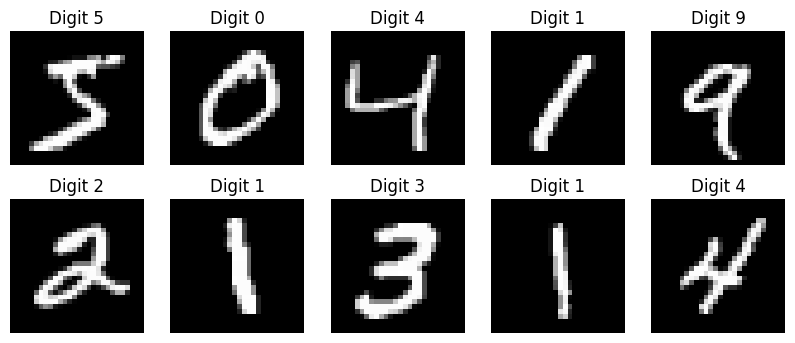

Normalized training shape: (60000, 784)
Normalized testing shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Dataset preparation completed!


In [1]:
print("24BAD015 - Bala Harshini B")
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit " + str(y_train[i]))
    plt.axis('off')
plt.show()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)
print("Normalized training shape:", x_train.shape)
print("Normalized testing shape:", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Dataset preparation completed!")

In [2]:
print("24BAD015 - Bala Harshini B")
from tensorflow.keras import layers, Model
input_layer = layers.Input(shape=(784,))
encoder_layer = layers.Dense(128, activation='relu')(input_layer)
bottleneck = layers.Dense(32, activation='relu')(encoder_layer)
encoder = Model(input_layer, bottleneck, name="Encoder")
decoder_input = layers.Input(shape=(32,))
decoder_layer = layers.Dense(128, activation='relu')(decoder_input)
decoder_output = layers.Dense(784, activation='sigmoid')(decoder_layer)
decoder = Model(decoder_input, decoder_output, name="Decoder")
autoencoder_output = decoder(encoder(input_layer))
autoencoder = Model(input_layer, autoencoder_output, name="Autoencoder")
autoencoder.compile(
    optimizer='adam',
    loss='mean_squared_error'
)
print("ENCODER SUMMARY")
encoder.summary()
print("DECODER SUMMARY")
decoder.summary()
print("AUTOENCODER SUMMARY")
autoencoder.summary()


24BAD015 - Bala Harshini B
ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

24BAD015 - Bala Harshini B
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - loss: 0.0598 - val_loss: 0.0337
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0272 - val_loss: 0.0217
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0198 - val_loss: 0.0176
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0169 - val_loss: 0.0155
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0152 - val_loss: 0.0142
Test Reconstruction MSE: 0.014211654663085938


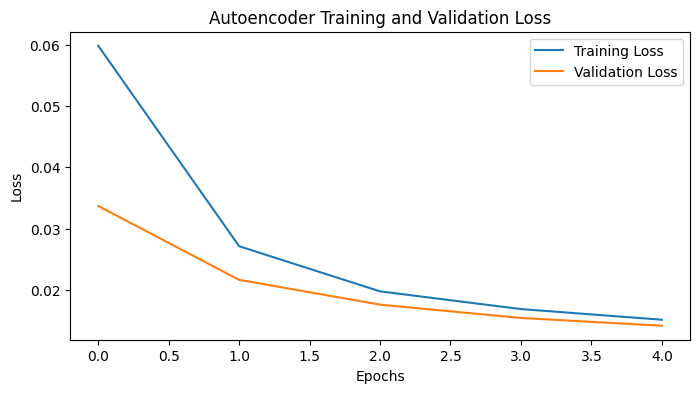

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


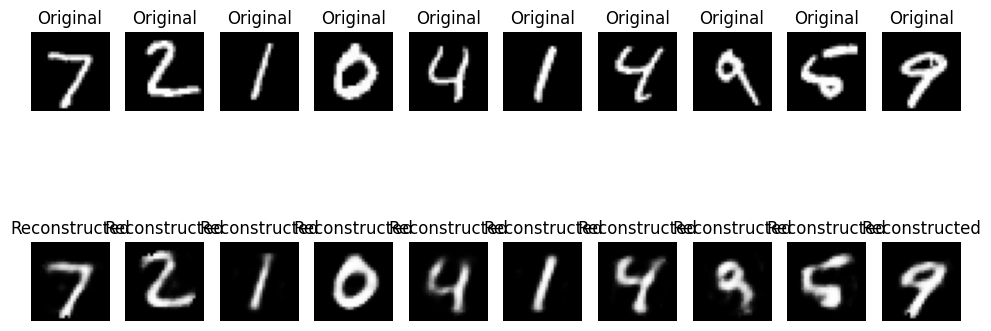

Model training completed!
Reconstruction evaluation completed!


In [3]:
print("24BAD015 - Bala Harshini B")
import matplotlib.pyplot as plt
import numpy as np
history = autoencoder.fit(
    x_train, x_train,
    epochs=5,
    batch_size=256,
    validation_data=(x_test, x_test)
)
test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)
print("Test Reconstruction MSE:", test_loss)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Autoencoder Training and Validation Loss")
plt.legend()
plt.show()
reconstructed_images = autoencoder.predict(x_test[:10])
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')
plt.show()
print("Model training completed!")
print("Reconstruction evaluation completed!")


24BAD015 - Bala Harshini B
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Original input dimensions: (1000, 784)
Compressed representation dimensions: (1000, 32)


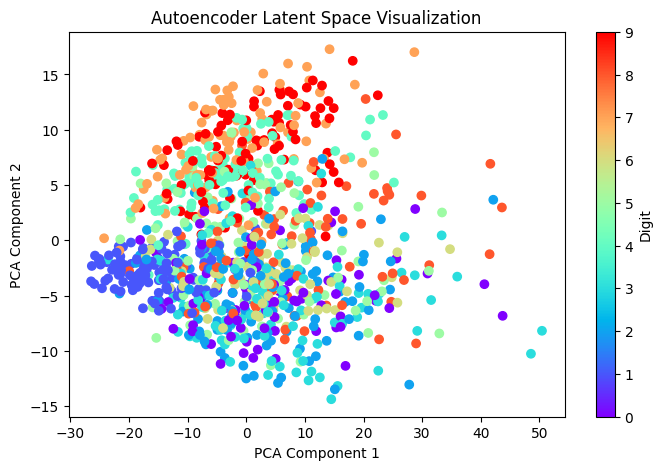

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


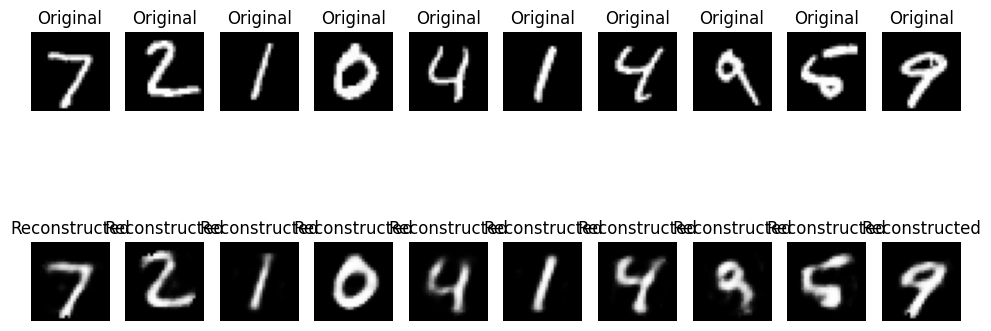

Feature extraction completed!
Dimensionality reduction completed!
Image reconstruction completed!
Autoencoder Experiment Completed Successfully!


In [4]:

print("24BAD015 - Bala Harshini B")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

latent_features = encoder.predict(x_test[:1000])

print("Original input dimensions:", x_test[:1000].shape)
print("Compressed representation dimensions:", latent_features.shape)
pca = PCA(n_components=2)
reduced_features = pca.fit_transform(latent_features)
plt.figure(figsize=(8, 5))
plt.scatter(
    reduced_features[:, 0],
    reduced_features[:, 1],
    c=y_test[:1000],
    cmap='rainbow'
)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Autoencoder Latent Space Visualization")
plt.colorbar(label="Digit")
plt.show()
selected_features = encoder.predict(x_test[:10])
reconstructed_images = decoder.predict(selected_features)
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')
plt.show()
print("Feature extraction completed!")
print("Dimensionality reduction completed!")
print("Image reconstruction completed!")
print("Autoencoder Experiment Completed Successfully!")